<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Survey Data:
   Pay  Benefits  Workload  Manager Support  Growth  Training  \
0    4         4         2                3       4         4   
1    2         2         2                2       1         1   
2    4         4         4                4       4         4   
3    5         5         4                3       5         5   
4    3         3         3                2       3         5   

   Salary Satisfaction  Team Spirit  Work Culture  Job Satisfaction  
0                    4            1             4                 2  
1                    4            2             1                 2  
2                    5            4             4                 5  
3                    5            5             4                 5  
4                    3            3             4                 3  


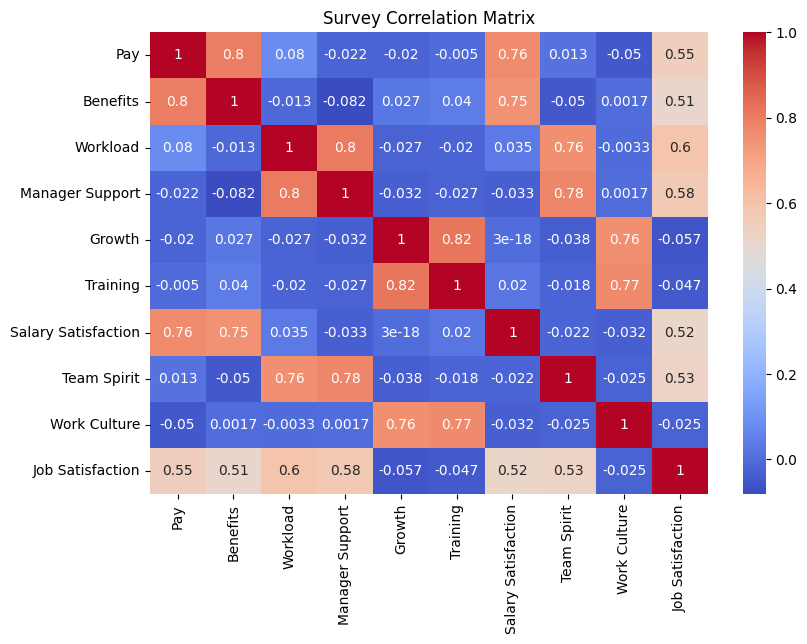


Factor Analysis with 2 Factors
                     Factor 1  Factor 2
Pay                     0.048    -1.266
Benefits               -0.060    -1.261
Workload                1.248    -0.055
Manager Support         1.296     0.070
Growth                 -0.065     0.007
Training               -0.053    -0.014
Salary Satisfaction     0.008    -1.201
Team Spirit             1.200     0.032
Work Culture           -0.019     0.041
Job Satisfaction        0.924    -0.847


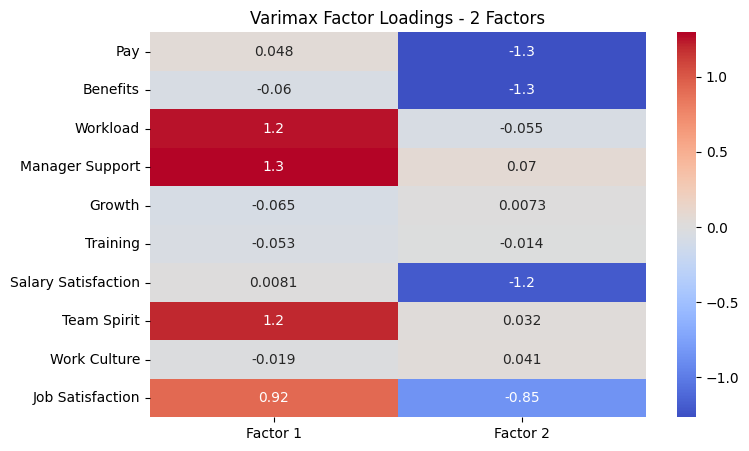


Factor Analysis with 3 Factors
                     Factor 1  Factor 2  Factor 3
Pay                     0.047     0.033    -1.266
Benefits               -0.059    -0.040    -1.262
Workload                1.248     0.009    -0.055
Manager Support         1.297     0.013     0.070
Growth                 -0.038    -1.267     0.000
Training               -0.025    -1.288    -0.023
Salary Satisfaction     0.008    -0.000    -1.201
Team Spirit             1.199     0.022     0.032
Work Culture            0.010    -1.195     0.037
Job Satisfaction        0.923     0.057    -0.847


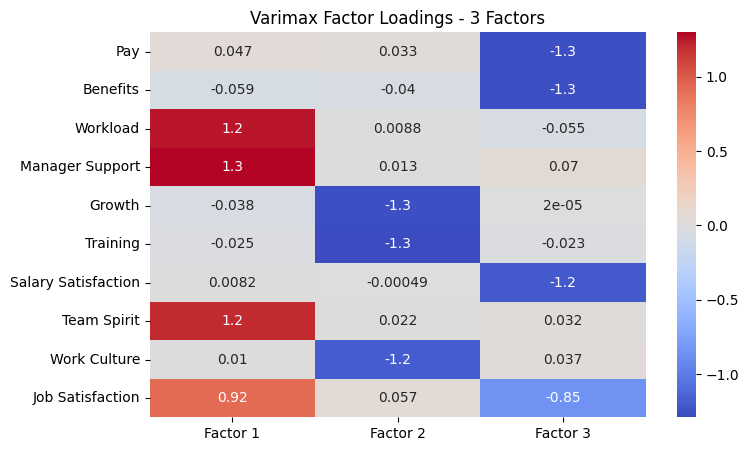


Factor Analysis with 4 Factors
                     Factor 1  Factor 2  Factor 3  Factor 4
Pay                     0.050     0.034    -1.279    -0.103
Benefits               -0.061    -0.040    -1.255     0.061
Workload                1.253     0.009    -0.058    -0.055
Manager Support         1.291     0.012     0.073     0.085
Growth                 -0.037    -1.263    -0.001    -0.034
Training               -0.021    -1.291    -0.025    -0.082
Salary Satisfaction     0.007    -0.001    -1.197     0.027
Team Spirit             1.208     0.023     0.030    -0.106
Work Culture            0.004    -1.203     0.042     0.147
Job Satisfaction        0.923     0.054    -0.848     0.293


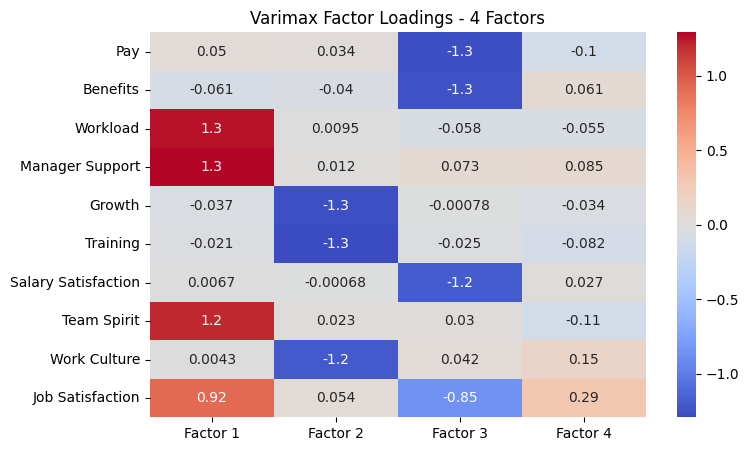


PCA Explained Variance:
[0.33146736 0.26126867 0.25289968]

Factor Analysis and PCA comparison:
Factor Analysis identifies hidden factors.
PCA identifies directions of maximum variance.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import FactorAnalysis, PCA

np.random.seed(42)

# Generate survey responses from 300 employees
n = 300

f1 = np.random.normal(size=n)
f2 = np.random.normal(size=n)
f3 = np.random.normal(size=n)

X = np.column_stack([
    f1 + np.random.normal(0, 0.4, n),
    f1 + np.random.normal(0, 0.4, n),
    f2 + np.random.normal(0, 0.4, n),
    f2 + np.random.normal(0, 0.4, n),
    f3 + np.random.normal(0, 0.4, n),
    f3 + np.random.normal(0, 0.4, n),
    f1 + np.random.normal(0, 0.5, n),
    f2 + np.random.normal(0, 0.5, n),
    f3 + np.random.normal(0, 0.5, n),
    f1 + f2 + np.random.normal(0, 0.5, n)
])

questions = [
    'Pay', 'Benefits', 'Workload', 'Manager Support',
    'Growth', 'Training', 'Salary Satisfaction',
    'Team Spirit', 'Work Culture', 'Job Satisfaction'
]

# Convert values into Likert scale 1-5
data = pd.DataFrame(X, columns=questions)

data = data.apply(
    lambda col: pd.qcut(col, 5, labels=[1, 2, 3, 4, 5]).astype(int)
)

print("Survey Data:")
print(data.head())

# Correlation matrix
plt.figure(figsize=(9, 6))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title("Survey Correlation Matrix")
plt.show()

# Varimax rotation
def varimax(Phi, gamma=1.0, q=20, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0

    for i in range(q):
        d_old = d
        Lambda = Phi @ R
        u, s, vh = np.linalg.svd(
            Phi.T @ (
                Lambda**3 -
                (gamma/p) * Lambda @ np.diag(np.diag(Lambda.T @ Lambda))
            )
        )
        R = u @ vh
        d = np.sum(s)

        if d_old != 0 and d/d_old < 1 + tol:
            break

    return Phi @ R

# Factor analysis with 2, 3 and 4 factors
for count in [2, 3, 4]:
    fa = FactorAnalysis(n_components=count, random_state=42)
    fa.fit(data)

    rotated = varimax(fa.components_.T)

    loading_df = pd.DataFrame(
        rotated,
        index=questions,
        columns=[f'Factor {i+1}' for i in range(count)]
    )

    print(f"\nFactor Analysis with {count} Factors")
    print(loading_df.round(3))

    plt.figure(figsize=(8, 5))
    sns.heatmap(loading_df, annot=True, cmap='coolwarm',
                center=0)
    plt.title(f"Varimax Factor Loadings - {count} Factors")
    plt.show()

# PCA comparison
pca = PCA(n_components=3)
pca.fit(data)

print("\nPCA Explained Variance:")
print(pca.explained_variance_ratio_)

print("\nFactor Analysis and PCA comparison:")
print("Factor Analysis identifies hidden factors.")
print("PCA identifies directions of maximum variance.")